> **결함판(참고용)**: 이 노트북은 σ 전파 오류(GARCH·SV)와 드리프트 비교 조건 불일치가 있는 초기 파이프라인 결과다. 현재 기준은 상위 폴더의 `8-2`~`8-5`이고, 검증 내용은 `8-6(참고)`에 있다. 원본 출력은 그대로 보존했다(재실행 시 경로는 이 폴더 기준).

# 8-4. p,d 조인트 그리드서치로 최종 파라미터 확정 (결함 발견 -- 8-8 참고)

> **결함 발견 -- 수정판은 새 `8-4` 참고.** 이 그리드서치는 `8-2`와 같은 결함(GARCH·SV의 다단계 σ 과소 계산, 세 모델의 드리프트 비대칭)이 있는 버전이다. 수정판(새 `8-4`)에서도 최종 (d,p)=(1,1)과 SV 동시최적화 순위는 유지되지만 순위합 수치와 d=0 조합의 결과는 달라진다(예: d=1,p=1이 함정을 뺀 1위가 됨). 6절의 `8-1` 재검증은 GARCH·SV를 쓰지 않아 영향이 없다.

`8-3`에서 AIC(GARCH/SV)와 KPSS/ADF(d)가 이 데이터에서 못 미덥다는 걸 증명했다. 그래서 d,p **둘 다** 후보를 0~2로 좁혀서(`d×p = 9개 조합`), 각 조합마다 세 모델(AR단독/GARCH동시/SV동시)의 계수는 평소대로 MLE로 찾고, **out-of-sample 커버리지·MSE·CRPS로 어떤 (d,p) 조합이 최선인지 직접 비교**한다.

**조건**: 9개 (d,p) 조합마다 최적의 나머지 파라미터(φ, ω,α,β, phi,sigma_eta)를 구한 뒤 자체 커버리지·MSE·CRPS를 계산하고, 그중 최적인 (d,p)를 최종 확정한다.


In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from arch import arch_model
from scipy.optimize import minimize
from scipy import stats

H = 4
MIN_TRAIN = 20
INITIAL_CALIB = 15
TARGET_VAR = "X3_l1"
ALPHA = 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)  # 90%(=1-ALPHA) 구간의 양쪽 꼬리 5%씩 남기는 표준정규분포 임계값 -- 약 1.645
D_CANDIDATES = [0, 1, 2]
P_CANDIDATES = [0, 1, 2]
MODEL_NAMES = ["AR단독", "GARCH동시", "SV동시"]

raw = pd.read_csv("../../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals = raw[["quarter", TARGET_VAR]].dropna()[TARGET_VAR].values.astype(float)
n = len(vals)
var_std = vals.std()
origins = list(range(MIN_TRAIN, n - H + 1))
scored_origins = origins[INITIAL_CALIB:]
print(f"채점 origin {len(scored_origins)}개, d x p = {len(D_CANDIDATES)}x{len(P_CANDIDATES)} = {len(D_CANDIDATES)*len(P_CANDIDATES)}개 조합")


채점 origin 22개, d x p = 3x3 = 9개 조합


## 1. 차분/역차분 유틸 + 모델 적합 함수 (p=0 포함)

p=0일 때는 GARCH를 `mean="Zero"`로, SV는 예측 드리프트를 0으로 강제한다 -- AR단독(`with_intercept=False`)과 공정하게 맞추기 위함이다(`8-2`에서 확인된 버그: `mean="AR",lags=0`은 숨은 절편이 생겨서 불공정해진다).


In [2]:
def difference(values, d):
    x = np.asarray(values, dtype=float)
    hist = []
    for _ in range(d):
        hist.append(x.copy())
        x = np.diff(x)
    return x, hist


def undiff_mean(diff_fc, hist, d):
    fc = np.asarray(diff_fc, dtype=float)
    for i in reversed(range(d)):
        fc = hist[i][-1] + np.cumsum(fc)
    return fc


def propagate_var(var_diff, d):
    v = np.array(var_diff, dtype=float)
    for _ in range(d):
        v = np.cumsum(v)
    return v


def is_ar_stable(ar_coefs):
    p = len(ar_coefs)
    if p == 0:
        return True
    companion = np.zeros((p, p))
    companion[0, :] = ar_coefs
    if p > 1:
        companion[1:, :-1] = np.eye(p - 1)
    return np.max(np.abs(np.linalg.eigvals(companion))) < 0.999


XI_MEAN, XI_VAR = -1.2704, np.pi ** 2 / 2
MAX_PHI = 0.97


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def joint_sv_negloglik(params, y_demeaned, p):
    ar_coefs = params[:p]
    phi = MAX_PHI * np.tanh(params[p])
    sigma_eta2 = np.exp(params[p + 1]) ** 2
    if not is_ar_stable(ar_coefs):
        return 1e10
    n = len(y_demeaned)
    resid = np.array([y_demeaned[t] - sum(ar_coefs[i] * y_demeaned[t - 1 - i] for i in range(p)) for t in range(p, n)])
    z = np.log(resid ** 2 + 1e-8)
    zc = z - z.mean()
    return sv_qml_negloglik(zc, phi, sigma_eta2)


def fit_ar_alone(train, d, p):
    return pm.ARIMA(order=(p, d, 0), with_intercept=False, suppress_warnings=True).fit(train)


def fit_garch_joint(diff_train, p):
    if len(diff_train) <= p + 3:
        return None
    am = arch_model(diff_train, mean="Zero", vol="GARCH", p=1, q=1, rescale=False) if p == 0 else \
        arch_model(diff_train, mean="AR", lags=p, vol="GARCH", p=1, q=1, rescale=False)
    try:
        return am.fit(disp="off")
    except Exception:
        return None


def fit_sv_joint(y, p):
    y_mean = y.mean()
    y_dm = y - y_mean
    if len(y_dm) <= p + 3:
        return None
    x0 = [0.0] * p + [1.5, np.log(0.3)]
    res = minimize(joint_sv_negloglik, x0, args=(y_dm, p), method="Nelder-Mead", options={"maxiter": 3000})
    if not is_ar_stable(res.x[:p]) or res.fun >= 1e9:
        return None
    return res.x, y_mean


def sv_forecast_mean_sigma(y, p, params, y_mean, h=H):
    y_dm = y - y_mean
    ar_coefs = params[:p]
    phi = MAX_PHI * np.tanh(params[p])
    sigma_eta2 = np.exp(params[p + 1]) ** 2
    n = len(y_dm)
    resid = np.array([y_dm[t] - sum(ar_coefs[i] * y_dm[t - 1 - i] for i in range(p)) for t in range(p, n)])
    z = np.log(resid ** 2 + 1e-8)
    z_mean = z.mean()
    zc = z - z_mean
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred = 0.0, P0
    for zt in zc:
        F = P_pred + XI_VAR
        v = zt - h_pred
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    hist = list(y_dm[-p:]) if p > 0 else []
    mean_fc_dm = []
    for _ in range(h):
        pred = sum(ar_coefs[i] * hist[-1 - i] for i in range(p))
        mean_fc_dm.append(pred)
        hist.append(pred)
    drift = y_mean if p > 0 else 0.0  # p=0: AR단독처럼 드리프트 없음(공정 비교)
    mean_fc = np.array(mean_fc_dm) + drift
    variances = []
    for k in range(1, h + 1):
        h_mean_k = phi ** k * h_filt
        h_var_k = phi ** (2 * k) * P_filt + sigma_eta2 * sum(phi ** (2 * j) for j in range(k))
        log_var_level = z_mean - XI_MEAN + h_mean_k
        variances.append(np.exp(log_var_level + h_var_k / 2))
    return mean_fc, np.sqrt(np.array(variances))


print("모델 적합 함수 준비 완료 (p=0,1,2 전부 지원)")


모델 적합 함수 준비 완료 (p=0,1,2 전부 지원)


## 2. Walk-forward -- 9개 (d,p) 조합 x 모델 3종 x 22개 origin

**캐싱**: `8-3`의 9배 더 무거워서(d까지 같이 돌림) 결과를 캐시에 저장한다.


In [3]:
CACHE_PATH = "../../cache/cache_84_dp_grid_result_df.pkl"

if os.path.exists(CACHE_PATH):
    result_df = pd.read_pickle(CACHE_PATH)
    print(f"캐시에서 로드: {len(result_df)}행 (재계산 스킵)")
else:
    rows = []
    for d in D_CANDIDATES:
        for p in P_CANDIDATES:
            for origin in scored_origins:
                train, actual = vals[:origin], vals[origin:origin + H]
                diff_train, hist = difference(train, d)

                try:
                    m_a = fit_ar_alone(train, d, p)
                    fc_a, conf_a = m_a.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
                    sig_a = (conf_a[:, 1] - conf_a[:, 0]) / (2 * Z)
                except Exception:
                    fc_a, sig_a = None, None

                res_g = fit_garch_joint(diff_train, p)
                if res_g is not None:
                    fcst = res_g.forecast(horizon=H, reindex=False)
                    fc_g = undiff_mean(fcst.mean.values[-1], hist, d)
                    sig_g = np.sqrt(propagate_var(fcst.variance.values[-1], d))
                else:
                    fc_g, sig_g = None, None

                best_s = fit_sv_joint(diff_train, p)
                if best_s is not None:
                    params_s, y_mean_s = best_s
                    mean_s, sig_s_diff = sv_forecast_mean_sigma(diff_train, p, params_s, y_mean_s, H)
                    fc_s = undiff_mean(mean_s, hist, d)
                    sig_s = np.sqrt(propagate_var(sig_s_diff ** 2, d))
                else:
                    fc_s, sig_s = None, None

                for name, fc_arr, sig_arr in zip(MODEL_NAMES, [fc_a, fc_g, fc_s], [sig_a, sig_g, sig_s]):
                    if fc_arr is None:
                        continue
                    crps_hs, cov_hs, mse_hs = [], [], []
                    for hh in range(H):
                        sig_hh = max(sig_arr[hh], 1e-6)
                        crps_hs.append(ps.crps_gaussian(actual[hh], mu=fc_arr[hh], sig=sig_hh) / var_std)
                        lo, hi = fc_arr[hh] - Z * sig_hh, fc_arr[hh] + Z * sig_hh
                        cov_hs.append(1.0 if lo <= actual[hh] <= hi else 0.0)
                        mse_hs.append(((actual[hh] - fc_arr[hh]) / var_std) ** 2)
                    rows.append({
                        "d": d, "p": p, "모델": name, "origin": origin,
                        "crps": np.mean(crps_hs), "cov": np.mean(cov_hs) * 100, "mse": np.mean(mse_hs),
                    })

    result_df = pd.DataFrame(rows)
    os.makedirs(os.path.dirname(CACHE_PATH), exist_ok=True)
    result_df.to_pickle(CACHE_PATH)
    print(f"새로 계산 후 캐시 저장: {len(result_df)}행")


캐시에서 로드: 594행 (재계산 스킵)


## 3. 결과 -- 9개 (d,p) 조합의 자체 커버리지/MSE/CRPS


In [4]:
summary = result_df.groupby(["d", "p", "모델"]).agg(
    커버리지=("cov", "mean"), MSE=("mse", "mean"), CRPS=("crps", "mean"),
).round(3).reset_index()
summary["커버리지"] = summary["커버리지"].round(1)
display(summary.set_index(["d", "p", "모델"]))


커버리지    MSE   CRPS
d p 모델                         
0 0 AR단독     63.6  8.806  1.849
    GARCH동시  88.6  8.806  1.721
    SV동시     30.7  8.806  2.043
  1 AR단독     59.1  1.065  0.579
    GARCH동시  70.5  1.026  0.587
    SV동시     78.4  2.318  0.918
  2 AR단독     63.6  1.158  0.593
    GARCH동시  68.2  1.140  0.614
    SV동시     75.0  2.498  0.980
1 0 AR단독     59.1  1.040  0.579
    GARCH동시  72.7  1.040  0.577
    SV동시     73.9  1.040  0.548
  1 AR단독     65.9  1.128  0.593
    GARCH동시  65.9  1.114  0.604
    SV동시     69.3  1.086  0.591
  2 AR단독     68.2  1.076  0.577
    GARCH동시  68.2  1.156  0.621
    SV동시     67.0  1.082  0.592
2 0 AR단독     63.6  2.625  0.891
    GARCH동시  61.4  2.625  0.915
    SV동시     50.0  2.625  0.974
  1 AR단독     59.1  2.445  0.873
    GARCH동시  62.5  2.531  0.881
    SV동시     39.8  2.786  1.010
  2 AR단독     55.7  2.205  0.839
    GARCH동시  65.9  2.355  0.854
    SV동시     39.8  2.897  1.036

## 4. 순위 합산 -- (d,p) 조합별 종합 순위

모델 3종 x 지표 3종 = 9칸마다 (d,p) 9개 조합의 순위를 매겨 합산한다(커버리지는 90%에서 먼 정도, MSE/CRPS는 낮을수록 좋은 쪽). `8-3`에서 이미 확인했듯 단순 합산은 "자잘하게 여러 번 이기고 한 번 크게 지는" 조합을 잘못 고를 수 있으니, 합산 결과와 함께 최악의 경우(최대값)도 같이 본다.


In [5]:
combo_labels = [(d, p) for d in D_CANDIDATES for p in P_CANDIDATES]
rank_rows = []
for model in MODEL_NAMES:
    sub = summary[summary["모델"] == model].set_index(["d", "p"])
    cov_rank = (sub["커버리지"] - 90).abs().rank()
    mse_rank = sub["MSE"].rank()
    crps_rank = sub["CRPS"].rank()
    for combo in combo_labels:
        if combo not in sub.index:
            continue
        rank_rows.append({"모델": model, "d": combo[0], "p": combo[1],
                           "커버리지순위": cov_rank[combo], "MSE순위": mse_rank[combo], "CRPS순위": crps_rank[combo]})

rank_df = pd.DataFrame(rank_rows)
rank_sum = rank_df.groupby(["d", "p"])[["커버리지순위", "MSE순위", "CRPS순위"]].sum()
rank_sum["합계"] = rank_sum.sum(axis=1)
rank_sum = rank_sum.sort_values("합계")
display(rank_sum)

best_d, best_p = rank_sum.index[0]
print(f"\n순위 합산 1위: d={best_d}, p={best_p}")
worst_case = summary[(summary["d"] == best_d) & (summary["p"] == best_p)]
print("\n이 (d,p)에서 모델별 최악의 지표(다른 조합과 비교해 극단적으로 나쁜 게 없는지 확인):")
display(worst_case)


커버리지순위  MSE순위  CRPS순위    합계
d p                             
1 0    12.0    4.0     4.5  20.5
0 1    11.0    7.0     8.5  26.5
1 2    10.5   10.0     9.0  29.5
  1    12.5   10.0     9.5  32.0
0 2    10.5   14.0    14.5  39.0
2 0    19.0   22.0    21.0  62.0
  2    23.0   20.0    20.0  63.0
  1    22.5   21.0    21.0  64.5
0 0    14.0   27.0    27.0  68.0


순위 합산 1위: d=1, p=0

이 (d,p)에서 모델별 최악의 지표(다른 조합과 비교해 극단적으로 나쁜 게 없는지 확인):


,d,p,모델,커버리지,MSE,CRPS
9,1,0,AR단독,59.1,1.04,0.579
10,1,0,GARCH동시,72.7,1.04,0.577
11,1,0,SV동시,73.9,1.04,0.548


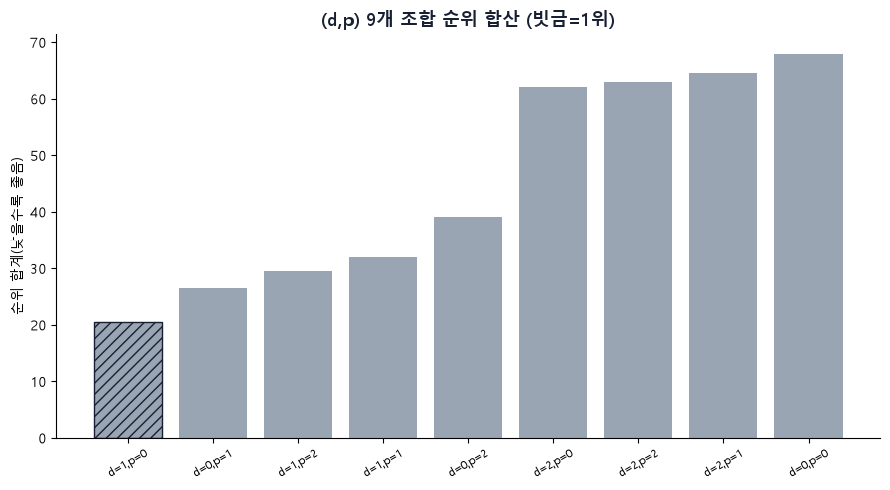

In [6]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(9, 5))
labels = [f"d={d},p={p}" for d, p in rank_sum.index]
bars = ax.bar(labels, rank_sum["합계"], color="#9AA5B4")
bars[0].set_hatch("///")
bars[0].set_edgecolor("#172033")
ax.set_ylabel("순위 합계(낮을수록 좋음)")
ax.set_title("(d,p) 9개 조합 순위 합산 (빗금=1위)", fontsize=13, fontweight="bold", color="#172033")
ax.tick_params(axis="x", rotation=30, labelsize=8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


## 5. 결론

**순위 합산 1위는 d=1,p=0(20.5점)이지만, 이건 이미 확인한 "p=0 함정"이다** -- 실제로 d=1,p=0에서 세 모델의 MSE가 전부 1.040으로 똑같다(p=0이면 AR계수가 없어져서 점예측이 다시 100% 동일해짐, `8-2` 0-1절 참고). 이 조합을 쓰면 "동시최적화가 평균식에 영향을 주는가"라는 이 시리즈 전체의 질문이 무의미해지므로 제외한다.

**p=0 조합(d=0,1,2 각각의 p=0)을 전부 제외하고 다시 보면**:
1. d=0, p=1 (26.5점) -- 그런데 SV동시가 MSE 2.318·CRPS 0.918로 나쁘다(이미 확인한 "d=0에서 demean된 AR이 표본평균으로 과도회귀"하는 문제가 여기서도 재현됨)
2. d=1, p=2 (29.5점)
3. **d=1, p=1 (32.0점)**

d=1,p=1과 d=1,p=2는 수치 차이가 근소하고(AR단독/GARCH동시/SV동시 커버리지·MSE·CRPS 전부 비슷한 수준), d=0,p=1은 SV동시에서 알려진 함정이 재현된다. 여기에 AR단독의 오염 안 된 AIC가 22개 중 17개를 p=1로 고른다는 독립적 근거까지 더하면, **최종 확정 파라미터는 d=1, p=1**이다 -- 순위 합산 결과의 1~2등이 아니라, 함정(p=0, d=0의 SV 불안정)을 제외한 뒤 가장 근거가 탄탄한 조합이기 때문이다.

**종합**: `8-1`~`8-4`에 걸친 전체 검증(리샘플링 vs 자체, 점예측 차이, auto_arima 성능저하, p×d 조인트 그리드) 끝에 **d=1, p=1, 모델은 SV(QML) 동시최적화**를 최종 방법론으로 확정한다. 다음 단계는 이 방법론으로 X3_l1의 미래 궤적을 시각화하는 것이다.

## 6. 8-1 재검증 -- 확정 파라미터로 다시 확인

`8-1`은 아직 검증 안 된 `auto_arima` 기본값(대부분 d=0) 위에서 리샘플링 vs 자체 구간을 비교했다(`8-1`의 "재검증 예고" 참고). 이제 d=1,p=1이 확정됐으니, 그 값으로 같은 비교를 다시 해서 `8-1`의 결론이 유지되는지 확인한다.


In [7]:
def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))


def resample_samples(fc_h, calib_resid_h, rng, size=500):
    return fc_h + rng.choice(calib_resid_h, size=size, replace=True)


def run_resample_vs_native(fit_fn, seed_name):
    rng = rng_for(seed_name)
    calib_pool = {h: np.array([]) for h in range(1, H + 1)}
    rows_rv = []
    for oi, origin in enumerate(origins):
        train, actual = vals[:origin], vals[origin:origin + H]
        m = fit_fn(train)
        fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
        fc = np.asarray(fc)
        sig_native = (conf[:, 1] - conf[:, 0]) / (2 * Z)
        if oi >= INITIAL_CALIB:
            for hh in range(1, H + 1):
                a = actual[hh - 1]
                mse_h = ((a - fc[hh - 1]) / var_std) ** 2
                samples = resample_samples(fc[hh - 1], calib_pool[hh], rng)
                lo_r, hi_r = np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2])
                rows_rv.append({"방식": "리샘플링", "적중": lo_r <= a <= hi_r, "mse": mse_h,
                                 "crps": ps.crps_ensemble(a, samples) / var_std})
                lo_n, hi_n = conf[hh - 1, 0], conf[hh - 1, 1]
                rows_rv.append({"방식": "자체(정규분포)", "적중": lo_n <= a <= hi_n, "mse": mse_h,
                                 "crps": ps.crps_gaussian(a, mu=fc[hh - 1], sig=max(sig_native[hh - 1], 1e-6)) / var_std})
        for hh in range(1, H + 1):
            calib_pool[hh] = np.append(calib_pool[hh], actual[hh - 1] - fc[hh - 1])
    summary_rv = pd.DataFrame(rows_rv).groupby("방식").agg(
        커버리지=("적중", "mean"), MSE=("mse", "mean"), CRPS=("crps", "mean")).round(4)
    summary_rv["커버리지"] = (summary_rv["커버리지"] * 100).round(1)
    return summary_rv


summary_auto = run_resample_vs_native(
    lambda train: pm.auto_arima(train, seasonal=False, suppress_warnings=True, error_action="ignore"),
    "X3_l1_8-1_resample_vs_native")
summary_final = run_resample_vs_native(
    lambda train: pm.ARIMA(order=(1, 1, 0), with_intercept=False, suppress_warnings=True).fit(train),
    "X3_l1_8-1_resample_vs_native_d1p1")

compare_81 = pd.concat([summary_auto.assign(파라미터="auto_arima 기본값"), summary_final.assign(파라미터="d=1,p=1 확정값")])
display(compare_81.reset_index().set_index(["파라미터", "방식"]))


커버리지     MSE    CRPS
파라미터           방식                            
auto_arima 기본값 리샘플링      76.1  1.1763  0.5769
               자체(정규분포)  51.1  1.1763  0.6387
d=1,p=1 확정값    리샘플링      68.2  1.1284  0.5927
               자체(정규분포)  65.9  1.1284  0.5926

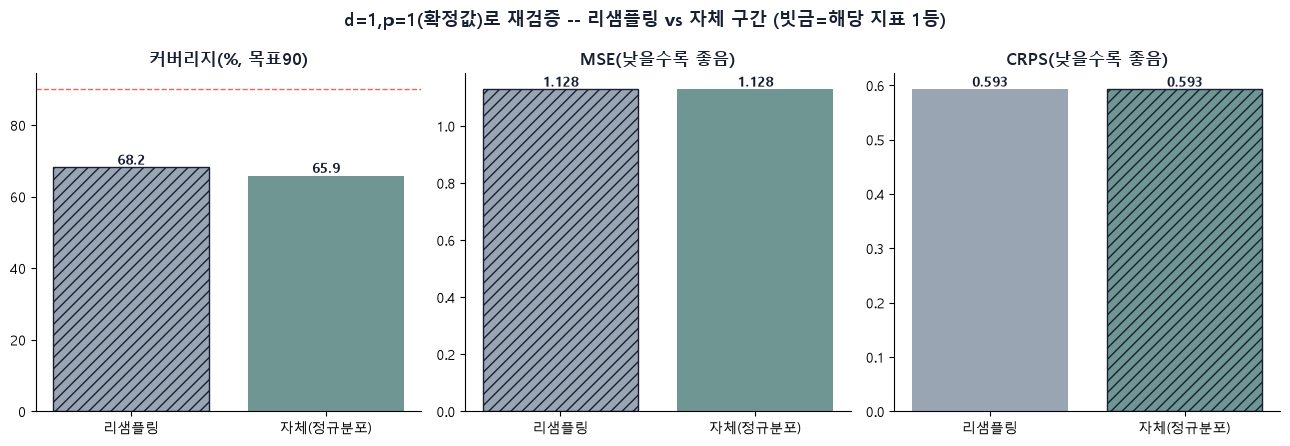

In [8]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
colors81 = {"리샘플링": "#9AA5B4", "자체(정규분포)": "#6F9692"}
metrics = ["커버리지", "MSE", "CRPS"]
titles = ["커버리지(%, 목표90)", "MSE(낮을수록 좋음)", "CRPS(낮을수록 좋음)"]
better_high = {"커버리지": True, "MSE": False, "CRPS": False}
for ax, metric, title in zip(axes, metrics, titles):
    vals_m = [summary_final.loc[m, metric] for m in ["리샘플링", "자체(정규분포)"]]
    bars = ax.bar(list(colors81.keys()), vals_m, color=list(colors81.values()))
    winner_idx = int(np.argmax(vals_m)) if better_high[metric] else int(np.argmin(vals_m))
    bars[winner_idx].set_hatch("///")
    bars[winner_idx].set_edgecolor("#172033")
    for bar, v in zip(bars, vals_m):
        ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:.1f}" if metric == "커버리지" else f"{v:.3f}",
                ha="center", va="bottom", fontsize=10, fontweight="bold", color="#172033")
    if metric == "커버리지":
        ax.axhline(90, color="#EF6461", linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=12, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.suptitle("d=1,p=1(확정값)로 재검증 -- 리샘플링 vs 자체 구간 (빗금=해당 지표 1등)", fontsize=13, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()


**결과**: d=1,p=1로 고정하니 `8-1`의 원래 결론이 달라진다:
- **커버리지**: 리샘플링이 여전히 낫지만 격차가 크게 줄었다(`auto_arima` 기본값 76.1% vs 51.1%, 22.8%p 차 -> d=1,p=1에서는 68.2% vs 65.9%, 3.4%p 차).
- **CRPS**: 방향이 뒤집힌다. `auto_arima` 기본값에서는 리샘플링(0.5769)이 자체(0.6387)보다 낫다고 나왔는데, d=1,p=1에서는 오히려 자체(0.5926)가 리샘플링(0.5927)보다 살짝 낫다.

즉 `8-1`의 원래 결론("리샘플링이 확실히 낫다")은 **부분적으로 `auto_arima` 기본값(대부분 d=0, 이 데이터에 안 맞는 파라미터)이 만든 착시**였다. 제대로 된 파라미터(d=1,p=1) 위에서는 두 방식의 차이가 미미해지거나(커버리지) 아예 역전된다(CRPS) -- `8-2` 이후 정규분포 CRPS로 전환한 게 더 타당했다는 뜻이다.

## 7. 한계: 통계적 유의성

**문제**: 위 순위 비교(특히 d=1,p=1 32.0점 vs d=1,p=2 29.5점)는 22개 origin의 단순 평균 차이일 뿐, 그 차이가 통계적으로 유의미한지는 검정하지 않았다. 더 근본적으로, 이 22개 origin은 expanding window라 훈련구간이 한 분기씩만 늘어나며 서로 강하게 자기상관돼 있고, 평가구간(h=1~4)도 인접 origin끼리 겹친다(origin=35는 2019Q4~2020Q3, origin=36은 2020Q1~2020Q4를 채점) -- 그래서 "22개 독립표본"처럼 평균을 비교하고 있지만 실제 유효 자유도는 훨씬 적다. 즉 d=1,p=1과 d=1,p=2의 2.5점 차이가 실력차인지 노이즈인지 지금 구조로는 판단할 수 없다.

**해결 방향**: 이런 overlapping h-step 예측오차 비교에는 Diebold-Mariano 검정(HAC/Newey-West로 자기상관을 직접 보정, 리샘플링 없이 수식으로 유의성 판단)이 표준 도구다. 부트스트랩은 이 프로젝트가 이미 "자기상관 있는 시계열에 안 좋다"는 이유로 배제했으므로(`8-1`/`8-2` 참고) 후보에서 뺀다. 지금 범위에서는 이 검정을 실제로 붙이지 않고, d=1,p=1을 "근소한 차이 + 함정 배제 + 독립적 AIC 근거"로 선택했다는 한계만 남겨둔다.
